<a href="https://colab.research.google.com/github/Handinoasa/MachineLearning_2026/blob/main/MLweek10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# JS Klasifikasi 2

- Nama: Handino Asa Galih R
- Kelas: TI 3E
- Nim: 244107020237

In [1]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns

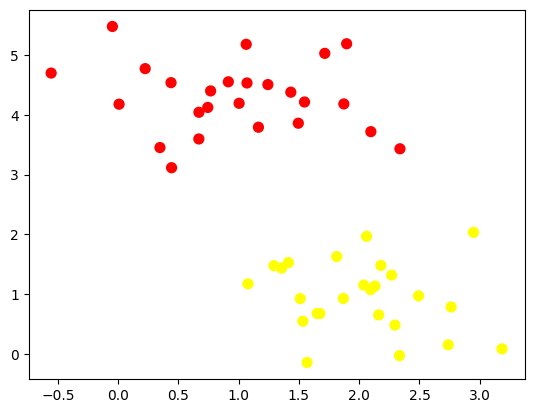

In [2]:
	from sklearn.datasets import make_blobs
	X, y = make_blobs(n_samples=50, centers=2,
	                  random_state=0, cluster_std=0.60)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

(-1.0, 3.5)

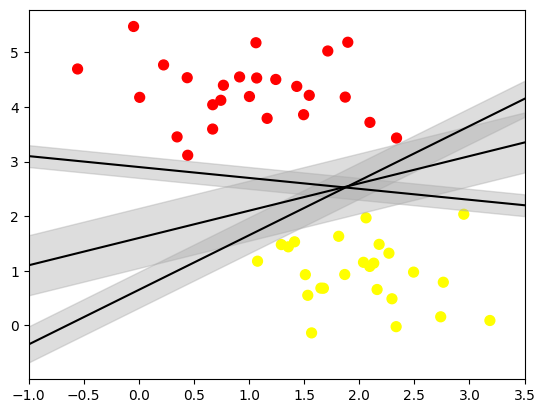

In [3]:
	xfit = np.linspace(-1, 3.5)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

	for m, b, d in [(1, 0.65, 0.33), (0.5, 1.6, 0.55), (-0.2, 2.9, 0.2)]:
	    yfit = m * xfit + b
	    plt.plot(xfit, yfit, '-k')
	    plt.fill_between(xfit, yfit - d, yfit + d, edgecolor='none',
	                     color='#AAAAAA', alpha=0.4)

	plt.xlim(-1, 3.5)

In [4]:
	from sklearn.svm import SVC # "Support vector classifier"
	model = SVC(kernel='linear', C=1E10)
	model.fit(X, y)

SVC(C=10000000000.0, kernel='linear')

In [5]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

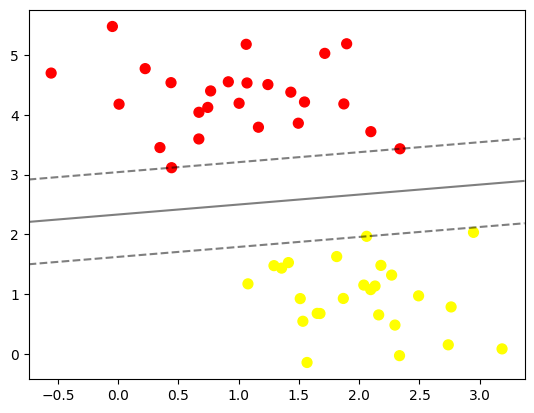

In [6]:
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(model)

In [7]:
model.support_vectors_

array([[0.44359863, 3.11530945],
       [2.33812285, 3.43116792],
       [2.06156753, 1.96918596]])

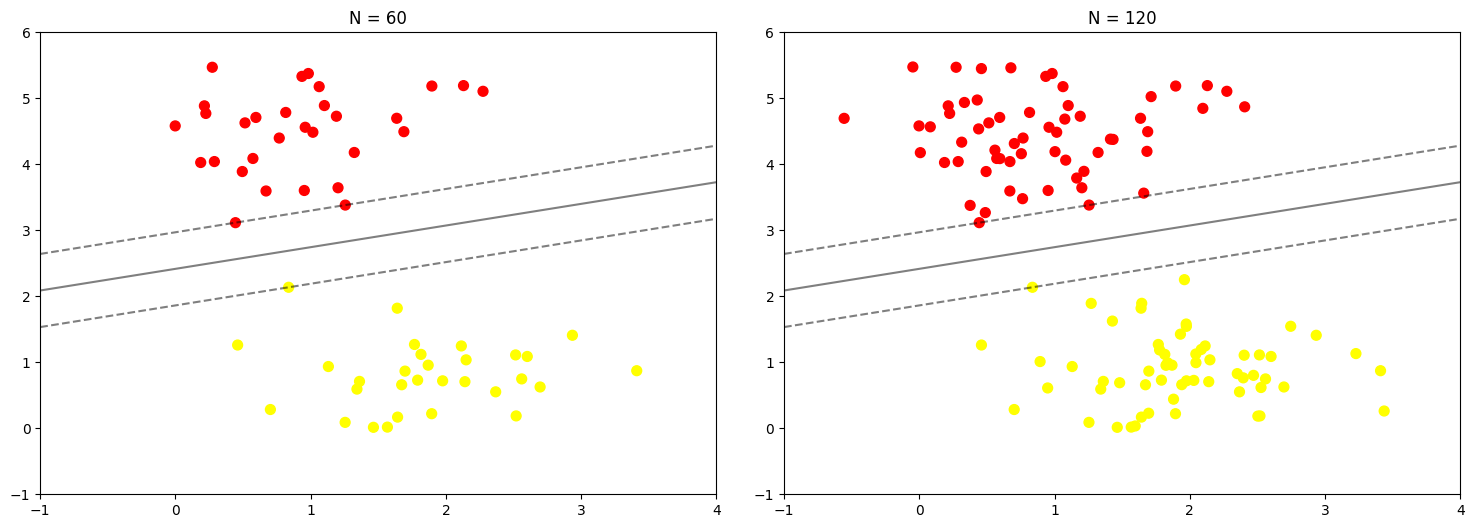

In [8]:
	def plot_svm(N=10, ax=None):
	    X, y = make_blobs(n_samples=200, centers=2,
	                      random_state=0, cluster_std=0.60)
	    X = X[:N]
	    y = y[:N]
	    model = SVC(kernel='linear', C=1E10)
	    model.fit(X, y)

	    ax = ax or plt.gca()
	    ax.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    ax.set_xlim(-1, 4)
	    ax.set_ylim(-1, 6)
	    plot_svc_decision_function(model, ax)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)
	for axi, N in zip(ax, [60, 120]):
	    plot_svm(N, axi)
	    axi.set_title('N = {0}'.format(N))

In [9]:
	# jumlah data dapat dipilih di antara 10 atau 200 buah data, telihat tidak ada perubahan pada model

	from ipywidgets import interact, fixed
	interact(plot_svm, N=[10, 200], ax=fixed(None))

interactive(children=(Dropdown(description='N', options=(10, 200), value=10), Output()), _dom_classes=('widget…

<function __main__.plot_svm(N=10, ax=None)>

In [10]:
!pip install ipywidgets

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 14.9 MB/s  0:00:00


In [11]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC

In [12]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

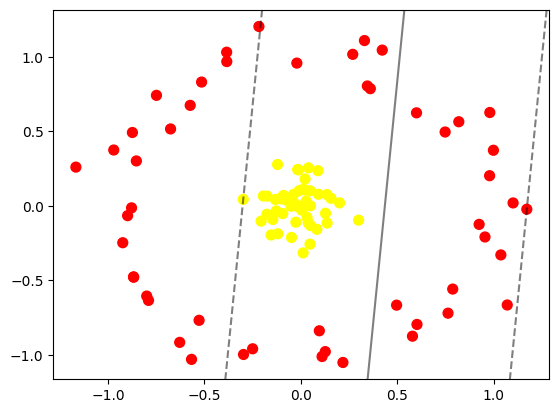

In [13]:
	# contoh data tidak terpisah secara linier
	from sklearn.datasets import make_circles
	X, y = make_circles(100, factor=.1, noise=.1)

	clf = SVC(kernel='linear').fit(X, y)

	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	plot_svc_decision_function(clf, plot_support=False);

In [15]:
!pip install ipywidgets

In [17]:
!pip install mpl_toolkits

ERROR: Could not find a version that satisfies the requirement mpl_toolkits (from versions: none)
ERROR: No matching distribution found for mpl_toolkits


In [18]:
import numpy as np
import matplotlib.pyplot as plt
from mpl_toolkits import mplot3d
from ipywidgets import interact, fixed

# 1. BUAT DATA CONTOH (Pastikan X, y, dan r sudah ada)
# (Bagian ini bisa Anda hapus/sesuaikan jika Anda sudah punya data X dan y sendiri)
np.random.seed(42)
X = np.random.randn(100, 2)
y = (X[:, 0]**2 + X[:, 1]**2 > 1).astype(int) # Label 0 atau 1

# PENTING: Definisikan variabel 'r' (misal r adalah fungsi radial untuk SVM Kernel RBF)
r = np.exp(-(X ** 2).sum(1))

# 2. DEFINISI FUNGSI PLOT 3D
def plot_3D(elev=30, azim=30, X=X, y=y):
    # Membersihkan figure agar plot tidak menumpuk saat slider digeser
    plt.figure(figsize=(8, 6))

    ax = plt.subplot(projection='3d')
    ax.scatter3D(X[:, 0], X[:, 1], r, c=y, s=50, cmap='autumn')
    ax.view_init(elev=elev, azim=azim)
    ax.set_xlabel('x')
    ax.set_ylabel('y')
    ax.set_zlabel('r')
    plt.show()

# 3. MENJALANKAN INTERACT (Perbaikan: azip diganti menjadi azim)
interact(plot_3D,
         elev=[-90, 45, 30, 20, 10],
         azim=(-180, 180),  # Diperbaiki dari azip menjadi azim
         X=fixed(X),
         y=fixed(y))


interactive(children=(Dropdown(description='elev', index=2, options=(-90, 45, 30, 20, 10), value=30), IntSlide…

<function __main__.plot_3D(elev=30, azim=30, X=array([[ 0.49671415, -0.1382643 ],
       [ 0.64768854,  1.52302986],
       [-0.23415337, -0.23413696],
       [ 1.57921282,  0.76743473],
       [-0.46947439,  0.54256004],
       [-0.46341769, -0.46572975],
       [ 0.24196227, -1.91328024],
       [-1.72491783, -0.56228753],
       [-1.01283112,  0.31424733],
       [-0.90802408, -1.4123037 ],
       [ 1.46564877, -0.2257763 ],
       [ 0.0675282 , -1.42474819],
       [-0.54438272,  0.11092259],
       [-1.15099358,  0.37569802],
       [-0.60063869, -0.29169375],
       [-0.60170661,  1.85227818],
       [-0.01349722, -1.05771093],
       [ 0.82254491, -1.22084365],
       [ 0.2088636 , -1.95967012],
       [-1.32818605,  0.19686124],
       [ 0.73846658,  0.17136828],
       [-0.11564828, -0.3011037 ],
       [-1.47852199, -0.71984421],
       [-0.46063877,  1.05712223],
       [ 0.34361829, -1.76304016],
       [ 0.32408397, -0.38508228],
       [-0.676922  ,  0.61167629],
       [ 1.03099952,  0.93128012],
       [-0.83921752, -0.30921238],
       [ 0.33126343,  0.97554513],
       [-0.47917424, -0.18565898],
       [-1.10633497, -1.19620662],
       [ 0.81252582,  1.35624003],
       [-0.07201012,  1.0035329 ],
       [ 0.36163603, -0.64511975],
       [ 0.36139561,  1.53803657],
       [-0.03582604,  1.56464366],
       [-2.6197451 ,  0.8219025 ],
       [ 0.08704707, -0.29900735],
       [ 0.09176078, -1.98756891],
       [-0.21967189,  0.35711257],
       [ 1.47789404, -0.51827022],
       [-0.8084936 , -0.50175704],
       [ 0.91540212,  0.32875111],
       [-0.5297602 ,  0.51326743],
       [ 0.09707755,  0.96864499],
       [-0.70205309, -0.32766215],
       [-0.39210815, -1.46351495],
       [ 0.29612028,  0.26105527],
       [ 0.00511346, -0.23458713],
       [-1.41537074, -0.42064532],
       [-0.34271452, -0.80227727],
       [-0.16128571,  0.40405086],
       [ 1.8861859 ,  0.17457781],
       [ 0.25755039, -0.07444592],
       [-1.91877122, -0.02651388],
       [ 0.06023021,  2.46324211],
       [-0.19236096,  0.30154734],
       [-0.03471177, -1.16867804],
       [ 1.14282281,  0.75193303],
       [ 0.79103195, -0.90938745],
       [ 1.40279431, -1.40185106],
       [ 0.58685709,  2.19045563],
       [-0.99053633, -0.56629773],
       [ 0.09965137, -0.50347565],
       [-1.55066343,  0.06856297],
       [-1.06230371,  0.47359243],
       [-0.91942423,  1.54993441],
       [-0.78325329, -0.32206152],
       [ 0.81351722, -1.23086432],
       [ 0.22745993,  1.30714275],
       [-1.60748323,  0.18463386],
       [ 0.25988279,  0.78182287],
       [-1.23695071, -1.32045661],
       [ 0.52194157,  0.29698467],
       [ 0.25049285,  0.34644821],
       [-0.68002472,  0.2322537 ],
       [ 0.29307247, -0.71435142],
       [ 1.86577451,  0.47383292],
       [-1.1913035 ,  0.65655361],
       [-0.97468167,  0.7870846 ],
       [ 1.15859558, -0.82068232],
       [ 0.96337613,  0.41278093],
       [ 0.82206016,  1.89679298],
       [-0.24538812, -0.75373616],
       [-0.88951443, -0.81581028],
       [-0.07710171,  0.34115197],
       [ 0.2766908 ,  0.82718325],
       [ 0.01300189,  1.45353408],
       [-0.26465683,  2.72016917],
       [ 0.62566735, -0.85715756],
       [-1.0708925 ,  0.48247242],
       [-0.22346279,  0.71400049],
       [ 0.47323762, -0.07282891],
       [-0.84679372, -1.51484722],
       [-0.44651495,  0.85639879],
       [ 0.21409374, -1.24573878],
       [ 0.17318093,  0.38531738],
       [-0.88385744,  0.15372511],
       [ 0.05820872, -1.1429703 ]]), y=array([0, 1, 0, 1, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 1, 1, 1, 1, 1, 0, 0,
       1, 1, 1, 0, 0, 1, 0, 1, 0, 1, 1, 1, 0, 1, 1, 1, 0, 1, 0, 1, 0, 0,
       0, 0, 0, 1, 0, 0, 1, 0, 0, 1, 0, 1, 1, 0, 1, 1, 1, 1, 1, 1, 0, 1,
       1, 1, 0, 1, 1, 1, 0, 1, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 0, 1, 0, 0,
       1, 1, 1, 1, 0, 0, 1, 0, 1, 0, 0, 1]))>

In [19]:
	clf = SVC(kernel='rbf', C=1E6)
	clf.fit(X, y)

SVC(C=1000000.0)

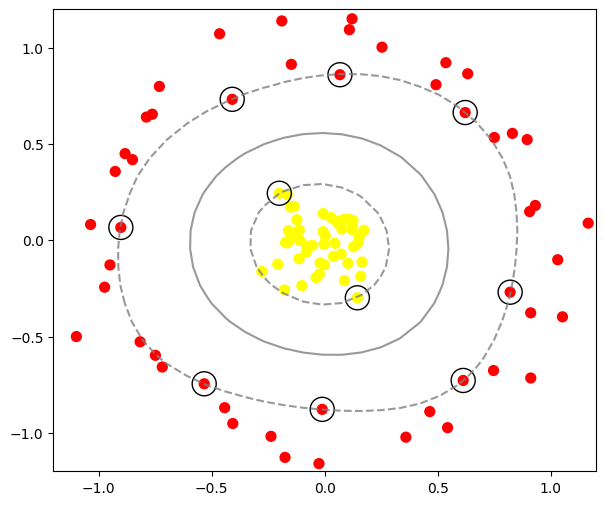

In [21]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import make_circles
from sklearn.svm import SVC

# 1. Membuat dataset berbentuk lingkaran (seperti pada gambar)
X, y = make_circles(100, factor=0.1, noise=0.1, random_state=0)

# 2. Membuat dan melatih model SVM dengan kernel RBF
clf = SVC(kernel='rbf', C=1E6)
clf.fit(X, y)

# 3. Mendefinisikan fungsi untuk membuat garis batas keputusan (Contour)
def plot_svc_decision_function(model, ax=None):
    if ax is None:
        ax = plt.gca()
    xlim = ax.get_xlim()
    ylim = ax.get_ylim()

    # Membuat grid untuk mengevaluasi model
    x = np.linspace(xlim[0], xlim[1], 30)
    y = np.linspace(ylim[0], ylim[1], 30)
    Y, X_grid = np.meshgrid(y, x)
    xy = np.vstack([X_grid.ravel(), Y.ravel()]).T
    P = model.decision_function(xy).reshape(X_grid.shape)

    # Plot batas keputusan (level=0) dan margin (level=-1 dan 1)
    ax.contour(X_grid, Y, P, colors='gray',
               levels=[-1, 0, 1], alpha=0.8,
               linestyles=['--', '-', '--'])

# 4. Membuat plot hasil sesuai langkah di gambar Anda
plt.figure(figsize=(7, 6))

# Menampilkan titik data asli
plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

# Menggambar batas keputusan (garis putus-putus abu-abu)
plot_svc_decision_function(clf)

# Menandai Support Vectors (lingkaran transparan besar terluar)
plt.scatter(clf.support_vectors_[:, 0], clf.support_vectors_[:, 1],
            s=300, lw=1, facecolors='none', edgecolors='black')

# Mengatur batas visual agar rapi
plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.show()


In [22]:
	# import library
	import numpy as np
	import matplotlib.pyplot as plt
	from scipy import stats
	import seaborn as sns
	from sklearn.svm import SVC
	from sklearn.datasets import make_blobs

In [23]:
	# buat sebuah fungsi untuk menampilkan fitting data

	def plot_svc_decision_function(model, ax=None, plot_support=True):

	    if ax is None:
	        ax = plt.gca()
	    xlim = ax.get_xlim()
	    ylim = ax.get_ylim()

	    # buat grid untuk evaluasi model
	    x = np.linspace(xlim[0], xlim[1], 30)
	    y = np.linspace(ylim[0], ylim[1], 30)
	    Y, X = np.meshgrid(y, x)
	    xy = np.vstack([X.ravel(), Y.ravel()]).T
	    P = model.decision_function(xy).reshape(X.shape)

	    # plot batas dan margin
	    ax.contour(X, Y, P, colors='k',
	               levels=[-1, 0, 1], alpha=0.5,
	               linestyles=['--', '-', '--'])

	    # plot support vectors
	    if plot_support:
	        ax.scatter(model.support_vectors_[:, 0],
	                   model.support_vectors_[:, 1],
	                   s=300, linewidth=1, facecolors='none');
	    ax.set_xlim(xlim)
	    ax.set_ylim(ylim)

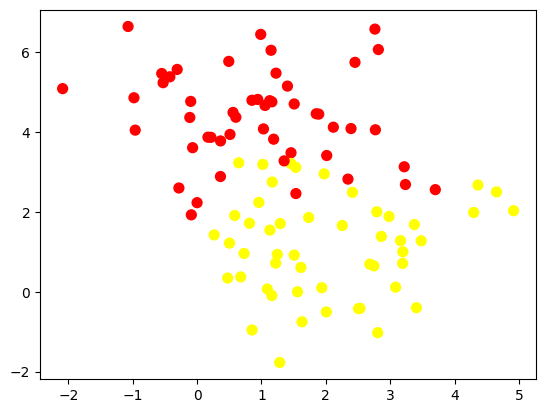

In [24]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=1.2)
	plt.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')

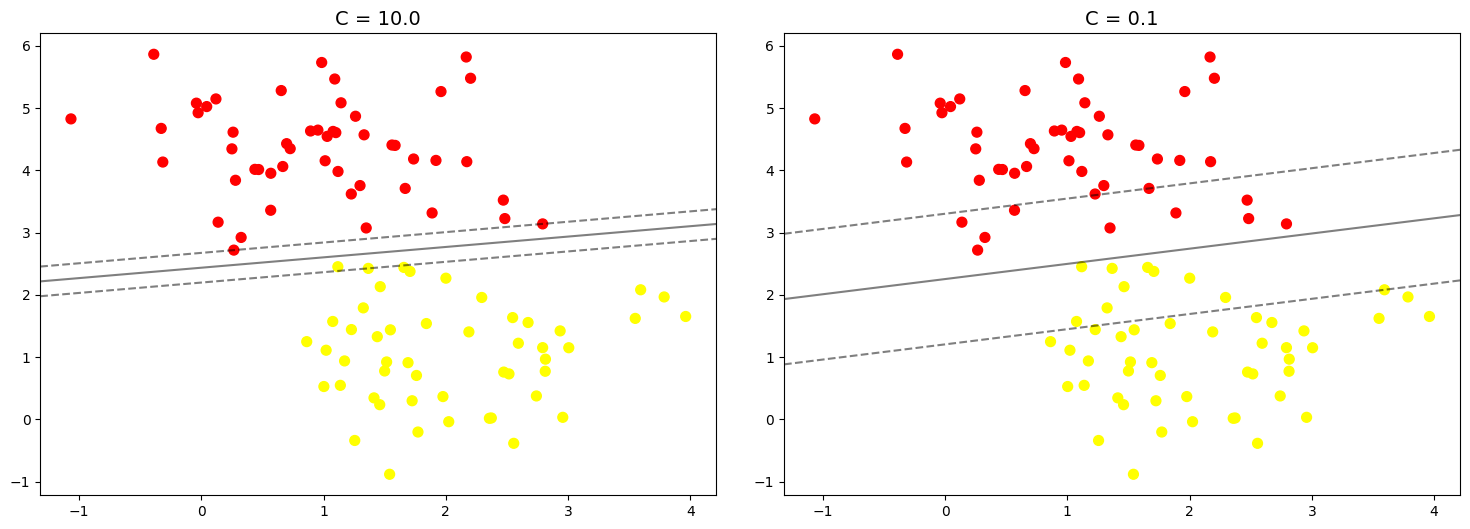

In [25]:
	X, y = make_blobs(n_samples=100, centers=2,
	                  random_state=0, cluster_std=0.8)

	fig, ax = plt.subplots(1, 2, figsize=(16, 6))
	fig.subplots_adjust(left=0.0625, right=0.95, wspace=0.1)

	for axi, C in zip(ax, [10.0, 0.1]):
	    model = SVC(kernel='linear', C=C).fit(X, y)
	    axi.scatter(X[:, 0], X[:, 1], c=y, s=50, cmap='autumn')
	    plot_svc_decision_function(model, axi)
	    axi.scatter(model.support_vectors_[:, 0],
	                model.support_vectors_[:, 1],
	                s=300, lw=1, facecolors='none');
	    axi.set_title('C = {0:.1f}'.format(C), size=14)

In [26]:
	from sklearn.datasets import fetch_lfw_people
	faces = fetch_lfw_people(min_faces_per_person=60)
	print(faces.target_names)
	print(len(faces.target_names))
	print(faces.images.shape)

['Ariel Sharon' 'Colin Powell' 'Donald Rumsfeld' 'George W Bush'
 'Gerhard Schroeder' 'Hugo Chavez' 'Junichiro Koizumi' 'Tony Blair']
8
(1348, 62, 47)


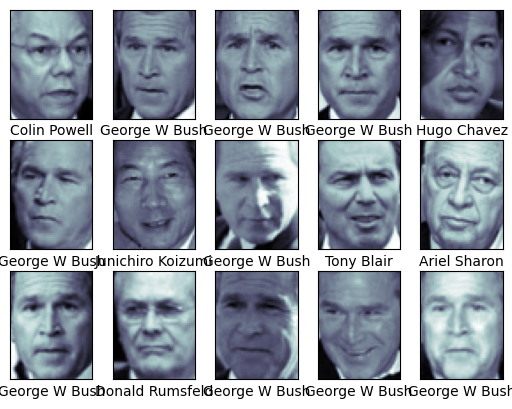

In [27]:
	# contoh wajah yang digunakan
	from matplotlib import pyplot as plt

	fig, ax = plt.subplots(3, 5)
	for i, axi in enumerate(ax.flat):
	    axi.imshow(faces.images[i], cmap='bone')
	    axi.set(xticks=[], yticks=[],
	            xlabel=faces.target_names[faces.target[i]])

In [28]:
	from sklearn.svm import SVC
	from sklearn.decomposition import PCA as RandomizedPCA
	from sklearn.pipeline import make_pipeline

	pca = RandomizedPCA(n_components=150, whiten=True, random_state=42)
	svc = SVC(kernel='rbf', class_weight='balanced')

	# Pipeline digunakan untuk melakukan proses secara bertahap dalam
	# 1 eksekusi fungsi secara langsung
	model = make_pipeline(pca, svc)

In [29]:
	# pemisahan data training dan data testing

	from sklearn.model_selection import train_test_split
	Xtrain, Xtest, ytrain, ytest = train_test_split(faces.data, faces.target, random_state=42)

In [31]:
from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC

# 1. Tentukan kombinasi hyperparameter yang ingin diuji
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': [1, 0.1, 0.01, 0.001]
}

# 2. Definisikan variabel 'grid' (Bagian ini yang belum ada/dijalankan)
grid = GridSearchCV(SVC(kernel='rbf'), param_grid, refit=True)

# 3. Latih grid search dengan data training Anda
# (Ganti Xtrain & ytrain dengan nama variabel data latih Anda)
grid.fit(Xtrain, ytrain)


GridSearchCV(estimator=SVC(),
             param_grid={'C': [0.1, 1, 10, 100],
                         'gamma': [1, 0.1, 0.01, 0.001]})

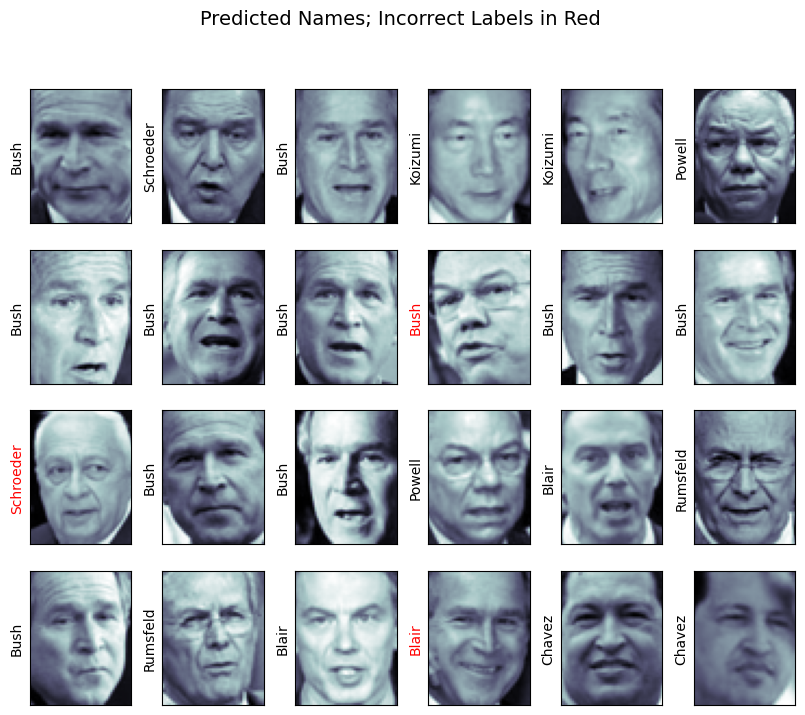

In [36]:
from sklearn.preprocessing import LabelEncoder

# Pastikan ytrain dan ytest adalah integer angka
le = LabelEncoder()
ytrain_encoded = le.fit_transform(ytrain)
ytest_encoded = le.transform(ytest)

# Latih ulang model menggunakan label yang sudah diubah ke angka
grid.fit(Xtrain, ytrain_encoded)
model = grid.best_estimator_
yfit = model.predict(Xtest) # Sekarang yfit dijamin berisi angka integer

# Setelah itu jalankan kode plot Anda yang asli (menggunakan ytest_encoded):
fig, ax = plt.subplots(4, 6, figsize=(10, 8))
for i, axi in enumerate(ax.flat):
    axi.imshow(Xtest[i].reshape(62, 47), cmap='bone')
    axi.set(xticks=[], yticks=[])
    axi.set_ylabel(faces.target_names[yfit[i]].split()[-1],
                   color='black' if yfit[i] == ytest_encoded[i] else 'red')
fig.suptitle('Predicted Names; Incorrect Labels in Red', size=14)
plt.show()


In [37]:
	from sklearn.metrics import classification_report
	print(classification_report(ytest, yfit,
	                            target_names=faces.target_names))

                   precision    recall  f1-score   support

     Ariel Sharon       0.69      0.73      0.71        15
     Colin Powell       0.84      0.82      0.83        68
  Donald Rumsfeld       0.70      0.68      0.69        31
    George W Bush       0.88      0.87      0.88       126
Gerhard Schroeder       0.72      0.78      0.75        23
      Hugo Chavez       1.00      0.65      0.79        20
Junichiro Koizumi       0.80      1.00      0.89        12
       Tony Blair       0.80      0.88      0.84        42

         accuracy                           0.82       337
        macro avg       0.80      0.80      0.80       337
     weighted avg       0.83      0.82      0.82       337



Text(113.92222222222219, 0.5, 'predicted label')

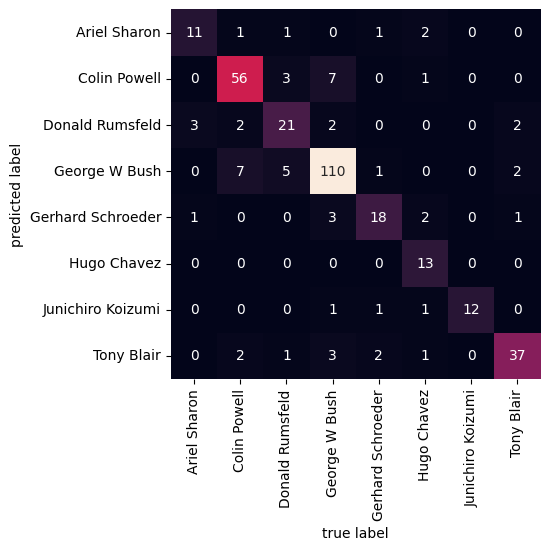

In [38]:
	# bentuk confusion matrix
	from sklearn.metrics import confusion_matrix
	import seaborn as sns

	mat = confusion_matrix(ytest, yfit)
	sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
	            xticklabels=faces.target_names,
	            yticklabels=faces.target_names)
	plt.xlabel('true label')
	plt.ylabel('predicted label')

Text(113.92222222222219, 0.5, 'predicted label')

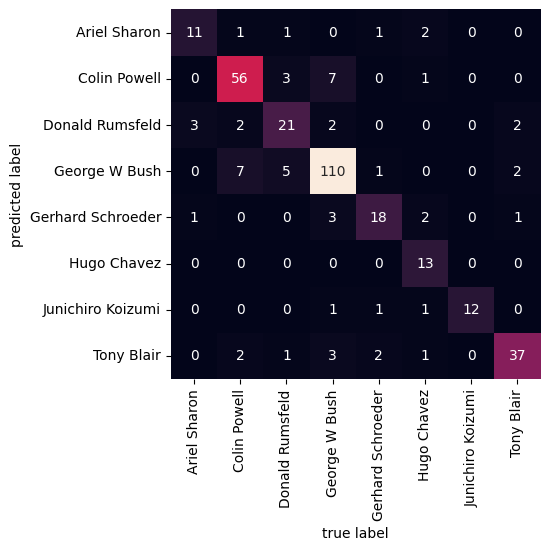

In [39]:
	# bentuk confusion matrix
	from sklearn.metrics import confusion_matrix
	import seaborn as sns

	mat = confusion_matrix(ytest, yfit)
	sns.heatmap(mat.T, square=True, annot=True, fmt='d', cbar=False,
	            xticklabels=faces.target_names,
	            yticklabels=faces.target_names)
	plt.xlabel('true label')
	plt.ylabel('predicted label')

In [40]:
	# Image directories
	train_dir = "images/training/"
	test_dir = "images/test/"

In [41]:
	def load_dataset(img_dir):
	    p = Path(img_dir)
	    dirs = p.glob('*')

	    img_list = []

	    for dir in dirs:
	        label = str(dir).split('/')[-1]
	        for file in dir.glob('*.jpg'):
	            img = mpimg.imread(file)

	            if not img is None:
	                img_list.append((img, label))

	    return img_list

In [51]:
# Download dataset images.zip langsung dari link modul praktikum
!wget -O images.zip "https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2FPS7Ex7o5Yo4EClMEuPGE%2Fimages.zip?alt=media&token=86b8ed48-d5b1-4ac0-bf07-1482521c21fc"

# Ekstrak file zip secara silent (-q) ke folder /content/
!unzip -q -o images.zip -d /content/

# Cek struktur folder hasil ekstraksi
!ls -la /content/images

--2026-11-03 20:29:56--  https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2FPS7Ex7o5Yo4EClMEuPGE%2Fimages.zip?alt=media&token=86b8ed48-d5b1-4ac0-bf07-1482521c21fc
Resolving 3041032130-files.gitbook.io (3041032130-files.gitbook.io)... 104.18.40.47, 172.64.147.209, 2a06:98c1:310d::6812:282f, ...
Connecting to 3041032130-files.gitbook.io (3041032130-files.gitbook.io)|104.18.40.47|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 28845089 (28M) [application/zip]
Saving to: ‘images.zip’

images.zip          100%[===================>]  27.51M  14.5MB/s    in 1.9s    

2026-11-03 20:29:59 (14.5 MB/s) - ‘images.zip’ saved [28845089/28845089]

total 16
drwxr-xr-x 4 root root 4096 Sep 17  2024 .
drwxr-xr-x 1 root root 4096 Nov  3 20:29 ..
drwxr-xr-x 4 root root 4096 Sep 17  2024 test
drwxr-xr-x 4 root root 4096 Sep 17  2024 training


In [52]:
from google.colab import drive
drive.mount('/content/drive')

# Sesuaikan path berikut dengan lokasi file images.zip di Google Drive Anda
!unzip -q -o "/content/drive/MyDrive/images.zip" -d /content/

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
unzip:  cannot find or open /content/drive/MyDrive/images.zip, /content/drive/MyDrive/images.zip.zip or /content/drive/MyDrive/images.zip.ZIP.


Jumlah data training: 240
Jumlah data testing : 160
Label  : day
Ukuran : (469, 640, 3)


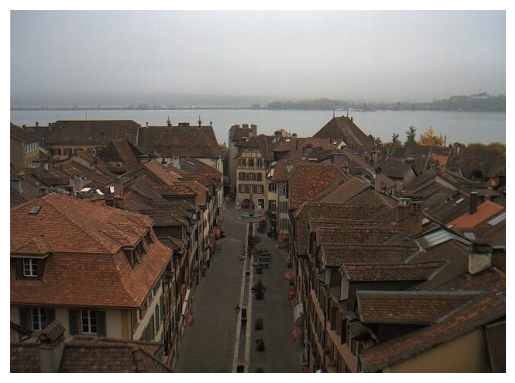

In [53]:
from pathlib import Path
import matplotlib.image as mpimg
import matplotlib.pyplot as plt
import cv2
import random
import numpy as np
import pandas as pd

# Image directories (sudah disesuaikan dengan lokasi ekstraksi di Colab)
train_dir = "/content/images/training/"
test_dir = "/content/images/test/"

def load_dataset(img_dir):
    p = Path(img_dir)
    dirs = p.glob('*')
    img_list = []

    for dir in dirs:
        label = dir.name
        for file in dir.glob('*.jpg'):
            img = mpimg.imread(file)
            if img is not None:
                img_list.append((img, label))
    return img_list

# Load data training dan testing
train_img = load_dataset(train_dir)
test_img = load_dataset(test_dir)

print(f"Jumlah data training: {len(train_img)}")
print(f"Jumlah data testing : {len(test_img)}")

# Visualisasi gambar secara acak
def random_img_viz(img_list):
    rand_num = random.randint(0, len(img_list) - 1)
    img = img_list[rand_num][0]
    label = img_list[rand_num][1]
    print(f"Label  : {label}")
    print(f"Ukuran : {img.shape}")
    plt.imshow(img)
    plt.axis('off')
    plt.show()

random_img_viz(train_img)

In [55]:
def standardize_input(image):
    # Resize ke width=1100, height=600
    std_img = cv2.resize(image, (1100, 600))
    return std_img

def label_encoder(label):
    # 1 untuk day, 0 untuk night
    return 1 if label == 'day' else 0

def preprocess(img_list):
    std_img_list = []
    for item in img_list:
        image = item[0]
        label = item[1]
        std_img = standardize_input(image)
        binary_label = label_encoder(label)
        std_img_list.append((std_img, binary_label))
    return std_img_list

train_std_img_list = preprocess(train_img)
test_std_img_list = preprocess(test_img)

# Verifikasi ukuran setelah resize
print(f"Ukuran gambar setelah standardisasi: {train_std_img_list[0][0].shape}")
print(f"Label setelah encoding             : {train_std_img_list[0][1]}")

Ukuran gambar setelah standardisasi: (600, 1100, 3)
Label setelah encoding             : 1


In [56]:
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, classification_report

# Fungsi ekstraksi fitur rata-rata brightness (channel V pada HSV)
def avg_brightness(image):
    hsv = cv2.cvtColor(image, cv2.COLOR_RGB2HSV)
    sum_brightness = np.sum(hsv[:, :, 2])
    area = image.shape[0] * image.shape[1]
    return sum_brightness / area

# Fungsi menyusun matriks fitur X dan vektor target y
def extract_features(std_img_list):
    X = []
    y = []
    for img, label in std_img_list:
        X.append([avg_brightness(img)])
        y.append(label)
    return np.array(X), np.array(y)

X_train, y_train = extract_features(train_std_img_list)
X_test, y_test = extract_features(test_std_img_list)

# Melatih model SVM
model = SVC()
model.fit(X_train, y_train)

# Prediksi dan evaluasi pada data training & testing
y_pred_train = model.predict(X_train)
y_pred_test = model.predict(X_test)

print(f"Akurasi Training: {accuracy_score(y_train, y_pred_train):.4f}")
print(f"Akurasi Testing : {accuracy_score(y_test, y_pred_test):.4f}")
print("\nLaporan Klasifikasi (Data Test):")
print(classification_report(y_test, y_pred_test, target_names=['night (0)', 'day (1)']))

Akurasi Training: 0.8583
Akurasi Testing : 0.9000

Laporan Klasifikasi (Data Test):
              precision    recall  f1-score   support

   night (0)       0.88      0.93      0.90        80
     day (1)       0.92      0.88      0.90        80

    accuracy                           0.90       160
   macro avg       0.90      0.90      0.90       160
weighted avg       0.90      0.90      0.90       160



# Soal 1 Klasifikasi Suara


In [57]:
# Download voice.csv langsung ke Google Colab
!wget -O voice.csv "https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2F4uIPAk2fE7hU8n1bM4kO%2Fvoice.csv?alt=media&token=3f846475-a72e-4ca2-bd03-24f2cbfca8c2"

import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score

# 1. Load dataset
df_voice = pd.read_csv('voice.csv')
print("Ukuran dataset voice.csv:", df_voice.shape)

# 2. Pisahkan fitur (X) dan target (y)
X_voice = df_voice.drop('label', axis=1)
y_voice = df_voice['label']

# 3. Encoding label ('male' / 'female' -> 1 / 0)
le = LabelEncoder()
y_voice_encoded = le.fit_transform(y_voice)

# 4. Standarisasi fitur numerik
scaler = StandardScaler()
X_voice_scaled = scaler.fit_transform(X_voice)

--2026-11-03 20:35:34--  https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2F4uIPAk2fE7hU8n1bM4kO%2Fvoice.csv?alt=media&token=3f846475-a72e-4ca2-bd03-24f2cbfca8c2
Resolving 3041032130-files.gitbook.io (3041032130-files.gitbook.io)... 104.18.40.47, 172.64.147.209, 2a06:98c1:310d::6812:282f, ...
Connecting to 3041032130-files.gitbook.io (3041032130-files.gitbook.io)|104.18.40.47|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 1065381 (1.0M) [text/csv]
Saving to: ‘voice.csv’

voice.csv           100%[===================>]   1.02M  --.-KB/s    in 0.07s   

2026-11-03 20:35:34 (15.3 MB/s) - ‘voice.csv’ saved [1065381/1065381]

Ukuran dataset voice.csv: (3168, 21)


In [58]:
# Definisi skenario rasio split dan kernel
split_ratios = {
    '70:30': 0.30,
    '80:20': 0.20
}
kernels = ['linear', 'poly', 'rbf']

results = []

for split_name, test_size in split_ratios.items():
    # Split data sesuai rasio
    X_tr, X_te, y_tr, y_te = train_test_split(
        X_voice_scaled, y_voice_encoded, test_size=test_size, random_state=42, stratify=y_voice_encoded
    )

    for kernel in kernels:
        # Inisialisasi dan latih model SVM
        svm_model = SVC(kernel=kernel, random_state=42)
        svm_model.fit(X_tr, y_tr)

        # Prediksi data train dan test
        y_pred_tr = svm_model.predict(X_tr)
        y_pred_te = svm_model.predict(X_te)

        # Hitung akurasi
        acc_tr = accuracy_score(y_tr, y_pred_tr)
        acc_te = accuracy_score(y_te, y_pred_te)

        results.append({
            'Rasio Split': split_name,
            'Kernel': kernel.capitalize(),
            'Akurasi Train': round(acc_tr, 4),
            'Akurasi Test': round(acc_te, 4),
            'Akurasi Test (%)': f"{acc_te * 100:.2f}%"
        })

# Tampilkan tabel tabulasi performansi
df_results = pd.DataFrame(results)
print("=== TABULASI PERFORMANSI MODEL SVM (VOICE.CSV) ===")
display(df_results)

=== TABULASI PERFORMANSI MODEL SVM (VOICE.CSV) ===


,Rasio Split,Kernel,Akurasi Train,Akurasi Test,Akurasi Test (%)
0,70:30,Linear,0.9720,0.9790,97.90%
1,70:30,Poly,0.9680,0.9590,95.90%
2,70:30,Rbf,0.9838,0.9832,98.32%
3,80:20,Linear,0.9763,0.9748,97.48%
4,80:20,Poly,0.9684,0.9574,95.74%
5,80:20,Rbf,0.9842,0.9826,98.26%


# Soal 2 Klasifikasi Citra Siang & Malam Dengan fitur Histogram + SVM RBF

In [59]:
from pathlib import Path
import matplotlib.image as mpimg
import cv2
import os

# Pastikan folder /content/images sudah ada (jika belum, otomatis download & unzip)
if not os.path.exists("/content/images"):
    !wget -O images.zip "https://3041032130-files.gitbook.io/~/files/v0/b/gitbook-x-prod.appspot.com/o/spaces%2F5CvtE8Xh9b75jKUaRr5Y%2Fuploads%2FPS7Ex7o5Yo4EClMEuPGE%2Fimages.zip?alt=media&token=86b8ed48-d5b1-4ac0-bf07-1482521c21fc"
    !unzip -q -o images.zip -d /content/

def load_and_preprocess_images(dirs):
    std_img_list = []
    for img_dir in dirs:
        p = Path(img_dir)
        for folder in p.glob('*'):
            if folder.is_dir():
                label = 1 if folder.name == 'day' else 0
                for file in folder.glob('*.jpg'):
                    img = mpimg.imread(file)
                    if img is not None:
                        # Resize standar 1100 x 600
                        std_img = cv2.resize(img, (1100, 600))
                        std_img_list.append((std_img, label))
    return std_img_list

# Muat seluruh gambar untuk di-split 80:20
all_images = load_and_preprocess_images(["/content/images/training/", "/content/images/test/"])
print(f"Total keseluruhan citra berhasil dimuat: {len(all_images)} gambar")

Total keseluruhan citra berhasil dimuat: 400 gambar


In [60]:
def extract_histogram_features(img_list, bins=32):
    features = []
    labels = []

    for img, label in img_list:
        # Konversi RGB ke HSV
        hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV)

        # Hitung histogram untuk masing-masing channel (H, S, V)
        hist_h = cv2.calcHist([hsv], [0], None, [bins], [0, 180])
        hist_s = cv2.calcHist([hsv], [1], None, [bins], [0, 256])
        hist_v = cv2.calcHist([hsv], [2], None, [bins], [0, 256])

        # Normalisasi masing-masing histogram agar skala seragam
        cv2.normalize(hist_h, hist_h)
        cv2.normalize(hist_s, hist_s)
        cv2.normalize(hist_v, hist_v)

        # Gabungkan (flatten) ketiga histogram menjadi 1 vektor fitur
        hist_feature = np.concatenate([hist_h, hist_s, hist_v]).flatten()

        features.append(hist_feature)
        labels.append(label)

    return np.array(features), np.array(labels)

# Ekstraksi fitur histogram untuk semua gambar
X_hist, y_hist = extract_histogram_features(all_images, bins=32)
print("Dimensi matriks fitur histogram (X_hist):", X_hist.shape)

# Split data dengan rasio 80:20
X_train_img, X_test_img, y_train_img, y_test_img = train_test_split(
    X_hist, y_hist, test_size=0.20, random_state=42, stratify=y_hist
)
print(f"Jumlah Data Training (80%): {len(X_train_img)} | Data Testing (20%): {len(X_test_img)}")

Dimensi matriks fitur histogram (X_hist): (400, 96)
Jumlah Data Training (80%): 320 | Data Testing (20%): 80


In [61]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import classification_report, confusion_matrix

# 1. Model SVM RBF Default (Baseline)
svm_rbf_default = SVC(kernel='rbf', random_state=42)
svm_rbf_default.fit(X_train_img, y_train_img)
y_pred_default = svm_rbf_default.predict(X_test_img)
acc_default = accuracy_score(y_test_img, y_pred_default)

print(f"Akurasi SVM RBF (Default Parameter) : {acc_default:.4f} ({acc_default*100:.2f}%)")

# 2. Hyperparameter Tuning dengan GridSearchCV pada Kernel RBF
param_grid = {
    'C': [0.1, 1, 10, 100],
    'gamma': ['scale', 'auto', 0.01, 0.1, 1, 10],
    'kernel': ['rbf']
}

grid_search = GridSearchCV(
    SVC(random_state=42),
    param_grid,
    cv=5,
    scoring='accuracy',
    n_jobs=-1
)
grid_search.fit(X_train_img, y_train_img)

# Evaluasi model terbaik hasil tuning
best_svm_rbf = grid_search.best_estimator_
y_pred_tuned_train = best_svm_rbf.predict(X_train_img)
y_pred_tuned_test = best_svm_rbf.predict(X_test_img)

acc_tuned_train = accuracy_score(y_train_img, y_pred_tuned_train)
acc_tuned_test = accuracy_score(y_test_img, y_pred_tuned_test)

print("\n=== HASIL HYPERPARAMETER TUNING SVM RBF (FITUR HISTOGRAM) ===")
print(f"Parameter Terbaik     : {grid_search.best_params_}")
print(f"Akurasi CV Terbaik    : {grid_search.best_score_:.4f} ({grid_search.best_score_*100:.2f}%)")
print(f"Akurasi Data Training : {acc_tuned_train:.4f} ({acc_tuned_train*100:.2f}%)")
print(f"Akurasi Data Testing  : {acc_tuned_test:.4f} ({acc_tuned_test*100:.2f}%)")

print("\nLaporan Klasifikasi (Model Terbaik pada Data Test 20%):")
print(classification_report(y_test_img, y_pred_tuned_test, target_names=['Night (0)', 'Day (1)']))

Akurasi SVM RBF (Default Parameter) : 1.0000 (100.00%)

=== HASIL HYPERPARAMETER TUNING SVM RBF (FITUR HISTOGRAM) ===
Parameter Terbaik     : {'C': 1, 'gamma': 'scale', 'kernel': 'rbf'}
Akurasi CV Terbaik    : 0.9969 (99.69%)
Akurasi Data Training : 1.0000 (100.00%)
Akurasi Data Testing  : 1.0000 (100.00%)

Laporan Klasifikasi (Model Terbaik pada Data Test 20%):
              precision    recall  f1-score   support

   Night (0)       1.00      1.00      1.00        40
     Day (1)       1.00      1.00      1.00        40

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80

